<a href="https://colab.research.google.com/github/hectoravil/CLASES-/blob/main/CLASE_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Clase: NumPy y Pandas**

Todos los ejemplos usan un caso de planta (producción y defectos de dos líneas). El código evita ciclos y condicionales: solo usa variables, operaciones y llamadas a funciones.

NumPy hace cálculos rápidos con muchos números a la vez, Pandas acomoda esos números en tablas con nombres de columnas y Matplotlib las grafica.


**1 Importar nuevas librerias**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 2.2.3


In [ ]:
import numpy as np

# Tiempo de ciclo (minutos) de 6 piezas
tiempos = np.array([4.2, 3.9, 4.5, 4.1, 5.0, 3.8])

print(tiempos)
print(type(tiempos))
print(tiempos.shape)   # (6,) -> 6 elementos en una dimensión

# Convertir todos los tiempos a segundos de un solo paso
segundos = tiempos * 60
print(segundos)

# Estadísticas básicas
print("Promedio:", tiempos.mean())
print("Desviación estándar:", tiempos.std())
print("Mínimo:", tiempos.min())
print("Máximo:", tiempos.max())

[4.2 3.9 4.5 4.1 5.  3.8]
<class 'numpy.ndarray'>
(6,)
[252. 234. 270. 246. 300. 228.]
Promedio: 4.25
Desviación estándar: 0.40311288741492757
Mínimo: 3.8
Máximo: 5.0


In [ ]:
# Comparar genera un True/False por cada pieza (por ejemplo, cuáles superan los 4 minutos)
print(tiempos > 4.0)

# Quedarse solo con las piezas que tardaron más de 4 minutos usando indexación booleana
print(tiempos[tiempos > 4.0])

[ True False  True  True  True False]
[4.2 4.5 4.1 5. ]


# **Pandas**

Un DataFrame es una tabla donde cada columna tiene nombre y se puede calcular, filtrar y resumir con una sola línea de código. Por dentro, cada columna es un arreglo de NumPy, así que df["Producidas"].mean() funciona igual que en el bloque anterior.

**Celda 5: crear una tabla de datos**

In [ ]:
import pandas as pd

# Producción de dos líneas (A y B) durante 5 días
datos = {
    "Dia":         [1, 1, 2, 2, 3, 3, 4, 4, 5, 5],
    "Linea":       ["A", "B", "A", "B", "A", "B", "A", "B", "A", "B"],
    "Producidas":  [52, 48, 50, 45, 50, 50, 60, 70, 30, 40],
    "Defectuosas": [12, 18, 10, 25, 15, 14, 9, 22, 11, 16],
    "Horas":       [8, 8, 8, 8, 8, 8, 8, 8, 8, 8],
}

df = pd.DataFrame(datos)
df

# Si el archivo ya está subido a Colab (icono de carpeta a la izquierda):
# df = pd.read_csv("produccion.csv")

,Dia,Linea,Producidas,Defectuosas,Horas
0,1,A,52,12,8
1,1,B,48,18,8
2,2,A,50,10,8
3,2,B,45,25,8
4,3,A,50,15,8
5,3,B,50,14,8
6,4,A,60,9,8
7,4,B,70,22,8
8,5,A,30,11,8
9,5,B,40,16,8


In [ ]:
df["Buenas"] = df["Producidas"] - df["Defectuosas"]
df["Pct_defectos"] = (df["Defectuosas"] / df["Producidas"] * 100).round(2)
df["Piezas_por_hora"] = df["Producidas"] / df["Horas"]

df

,Dia,Linea,Producidas,Defectuosas,Horas,Buenas,Pct_defectos,Piezas_por_hora
0,1,A,52,12,8,40,23.08,6.500
1,1,B,48,18,8,30,37.50,6.000
2,2,A,50,10,8,40,20.00,6.250
3,2,B,45,25,8,20,55.56,5.625
4,3,A,50,15,8,35,30.00,6.250
5,3,B,50,14,8,36,28.00,6.250
6,4,A,60,9,8,51,15.00,7.500
7,4,B,70,22,8,48,31.43,8.750
8,5,A,30,11,8,19,36.67,3.750
9,5,B,40,16,8,24,40.00,5.000


In [ ]:
display(df["Producidas"])                 # una columna
display(df[["Dia", "Linea"]])             # varias columnas (doble corchete)
display(df[df["Linea"] == "B"])           # solo las filas de la línea B
display(df[df["Pct_defectos"] > 3])       # filas con más de 3 % de defectos
display(df.sort_values("Pct_defectos", ascending=False).head(3))  # 3 peores

,Producidas
0,52
1,48
2,50
3,45
4,50
5,50
6,60
7,70
8,30
9,40


,Dia,Linea
0,1,A
1,1,B
2,2,A
3,2,B
4,3,A
5,3,B
6,4,A
7,4,B
8,5,A
9,5,B


,Dia,Linea,Producidas,Defectuosas,Horas,Buenas,Pct_defectos,Piezas_por_hora
1,1,B,48,18,8,30,37.50,6.000
3,2,B,45,25,8,20,55.56,5.625
5,3,B,50,14,8,36,28.00,6.250
7,4,B,70,22,8,48,31.43,8.750
9,5,B,40,16,8,24,40.00,5.000


,Dia,Linea,Producidas,Defectuosas,Horas,Buenas,Pct_defectos,Piezas_por_hora
0,1,A,52,12,8,40,23.08,6.500
1,1,B,48,18,8,30,37.50,6.000
2,2,A,50,10,8,40,20.00,6.250
3,2,B,45,25,8,20,55.56,5.625
4,3,A,50,15,8,35,30.00,6.250
5,3,B,50,14,8,36,28.00,6.250
6,4,A,60,9,8,51,15.00,7.500
7,4,B,70,22,8,48,31.43,8.750
8,5,A,30,11,8,19,36.67,3.750
9,5,B,40,16,8,24,40.00,5.000


,Dia,Linea,Producidas,Defectuosas,Horas,Buenas,Pct_defectos,Piezas_por_hora
3,2,B,45,25,8,20,55.56,5.625
9,5,B,40,16,8,24,40.00,5.000
1,1,B,48,18,8,30,37.50,6.000


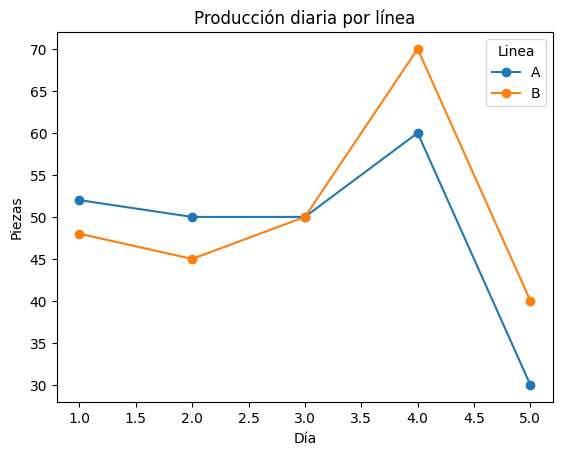

In [ ]:
# pivot: una fila por día y una columna por línea
tabla = df.pivot(index="Dia", columns="Linea", values="Producidas")

tabla.plot(marker="o", title="Producción diaria por línea",
           xlabel="Día", ylabel="Piezas")
plt.show()

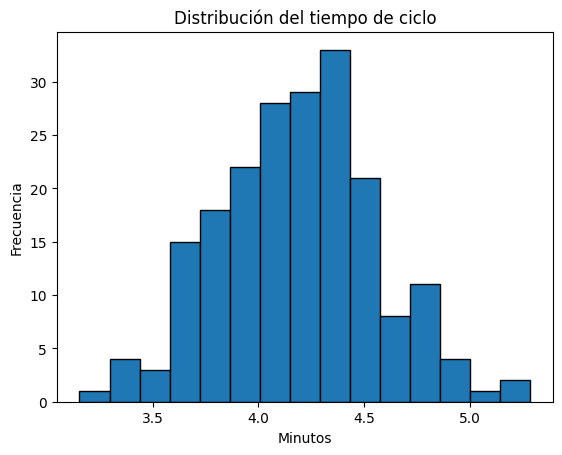

In [ ]:
np.random.seed(42)   # fija la semilla para repetir los mismos números
tiempos_ciclo = np.random.normal(loc=4.2, scale=0.4, size=200)

plt.hist(tiempos_ciclo, bins=15, edgecolor="black")
plt.title("Distribución del tiempo de ciclo")
plt.xlabel("Minutos")
plt.ylabel("Frecuencia")
plt.show()

El doble signo == compara; un solo = asigna. Las cuatro filas con más de 3 % de defectos son todas de la línea B (días 1, 2, 4 y 5).


**Celda 9: agrupar y resumir**

In [ ]:
resumen = df.groupby("Linea")[["Producidas", "Defectuosas"]].sum()
resumen["Pct_defectos"] = (resumen["Defectuosas"] / resumen["Producidas"] * 100).round(2)

print("Línea con mayor % de defectos:", resumen["Pct_defectos"].idxmax())
resumen

Línea con mayor % de defectos: B


,Producidas,Defectuosas,Pct_defectos
Linea,,,
A,2660,57,2.14
B,2395,95,3.97


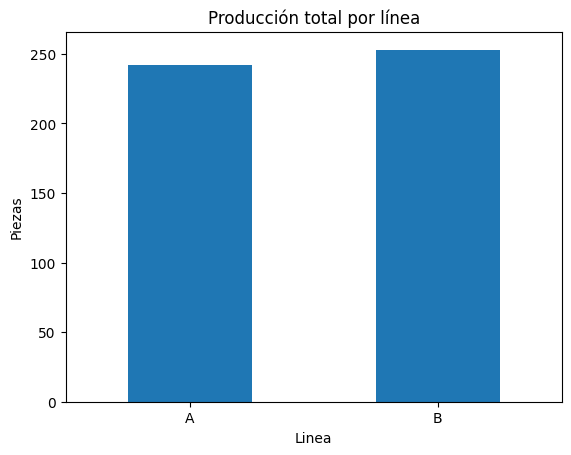

In [ ]:
import matplotlib.pyplot as plt

# Primero nos aseguramos de definir 'resumen' agrupando los datos
resumen = df.groupby("Linea")[["Producidas", "Defectuosas"]].sum()
resumen["Pct_defectos"] = (resumen["Defectuosas"] / resumen["Producidas"] * 40).round(2)

# Ahora graficamos
resumen["Producidas"].plot(kind="bar", title="Producción total por línea",
                           ylabel="Piezas", rot=0)
plt.show()